In [171]:
import torch
import matplotlib.pyplot as plt
import torch.nn as nn


%matplotlib inline
import slmsuite
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import matplotlib as mpl
from slmsuite.holography import toolbox
from slmsuite.holography.toolbox import phase
from matplotlib import pyplot as plt
from src.plots import *
from slmsuite.hardware.slms.simulated import SimulatedSLM
from slmsuite.hardware.cameras.simulated import SimulatedCamera
from slmsuite.hardware.cameraslms import FourierSLM
from slmsuite.holography.algorithms import FeedbackHologram
%load_ext autoreload
%autoreload 2
mpl.rc('image', cmap='Blues')

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [175]:
from slmsuite.hardware.cameraslms import FourierSLM

try:
    # Try to load physical hardware.
    from slmsuite.hardware.slms.santec import Santec
    from slmsuite.hardware.cameras.alliedvision import AlliedVision

    # Load the hardware.
    slm = Santec(slm_number=1, display_number=2, wav_um=.633, settle_time_s=.5); print()
    cam = AlliedVision(serial="02C5V", verbose=True, fliplr=True)

    # Load the composite CameraSLM.
    fs = FourierSLM(cam, slm)
    fs.read_calibration("wavefront_superpixel")
    fs.wavefront_calibration_superpixel_process(r2_threshold=.5, plot=True);
except Exception as e:
    print(f"Loading physical hardware failed; loading virtual hardware. Error:\n{str(e)}")
    # Fallback to virtual hardware.
    from slmsuite.hardware.slms.simulated import SimulatedSLM
    from slmsuite.hardware.cameras.simulated import SimulatedCamera

    # Make the SLM and camera.
    slm = SimulatedSLM((1600, 1200), pitch_um=(8,8))
    slm.set_source_analytic(sim=True)               # Program the virtual source.
    slm.set_source_analytic()                       # Don't bother with wavefront calibration, instead just set it to the same source.

    cam = SimulatedCamera(slm, (1440, 1100), pitch_um=(4,4), gain=200)

    # Tie the camera and SLM together with an analytic calibration.
    fs = FourierSLM(cam, slm)
    M, b = fs.fourier_calibration_build(
        f_eff=80000.,                              # f_eff of 80000 wavelengths or 80 mm with the default 1 um wavelength
        theta=5 * np.pi / 180,
    )
    cam.set_affine(M, b)
    fs.fourier_calibrate_analytic(M, b)

Loading physical hardware failed; loading virtual hardware. Error:
Santec DLLs not installed. Install these to use Santec SLMs.  Dynamically linked libraries from Santec (usually provided via USB) must be present in the runtime directory:
  - SLMFunc.dll
  - FTD3XX.dll
  Check that these files are present and are error-free.


In [303]:
from numpy import dtype


class SLMModel(nn.Module):
    def __init__(self, fs,citl = False):
        super().__init__()
        self.fs = fs
        self.slm_shape = fs.slm.shape
        self.phi_nf = nn.Parameter(torch.zeros(self.slm_shape))  # Learnable phase
        self.A_nf = torch.tensor(self.fs.slm.source['amplitude']/FeedbackHologram._norm(self.fs.slm.source['amplitude']),dtype=torch.float32)  # Fixed amplitude
        self.citl = citl  # Closed-loop mode (use camera)
        self.fholo = FeedbackHologram(shape = fs.slm.shape,cameraslm = fs)

    def forward(self):
        # Construct field in near field
        F_nf = self.A_nf * torch.exp(1j * self.phi_nf)

        # Propagate to far field
        F_ff = torch.fft.fftshift(torch.fft.fft2(torch.fft.fftshift(F_nf)))
        A_ff = torch.abs(F_ff)
        phi_ff = torch.angle(F_ff)

        if self.citl:
            # Write phase to SLM and get real camera image
            self.fs.slm.write(self.phi_nf.detach().cpu().numpy())
            A_cam = self.fs.cam.get_image()
            A_cam_ff = torch.tensor(self.fholo.ijcam_to_knmslm(A_cam)/FeedbackHologram._norm(self.fholo.ijcam_to_knmslm(A_cam)),dtype=torch.float32)
            A_cam_ff[torch.isnan(A_cam_ff)] = 0
            # Use A_cam_ff in loss, but keep gradients from A_ff
            # Equivalent to: A_out = A_cam_ff - (A_cam_ff - A_ff).detach()
            A_out = A_ff + (A_cam_ff - A_ff).detach()
        else:
            A_out = A_ff

        # Return simulated/measured amplitude for loss
        return A_out


In [432]:
A_target = np.zeros(fs.slm.shape)
A_target[400:420,400:420] = 1
model = SLMModel(fs,citl=True)
A_target_norm = torch.tensor(model.fholo.ijcam_to_knmslm(A_target)/FeedbackHologram._norm(model.fholo.ijcam_to_knmslm(A_target)),dtype=torch.float32)
A_target_norm[torch.isnan(A_target_norm)] = 0
optimizer = torch.optim.SGD(model.parameters(), lr=10000000000)
num_steps = 100
for step in range(num_steps):
    optimizer.zero_grad()
    A_out = model()
    loss = torch.nn.functional.mse_loss(A_out*A_out, A_target_norm*A_target_norm)
    loss.backward()
    optimizer.step()
    print(f"Step {step+1}/{num_steps}, Loss: {loss.item()*1e8}")

Step 1/100, Loss: 1.8625934572469305
Step 2/100, Loss: 1.8625931019755626
Step 3/100, Loss: 1.8625938125182984
Step 4/100, Loss: 1.8625931019755626
Step 5/100, Loss: 1.8280593039321502
Step 6/100, Loss: 0.9494020680733684
Step 7/100, Loss: 0.6129814877908757
Step 8/100, Loss: 0.6530152418804391
Step 9/100, Loss: 0.6873911662097498
Step 10/100, Loss: 0.607702421717704
Step 11/100, Loss: 0.7519094680219496
Step 12/100, Loss: 0.5955286930259263
Step 13/100, Loss: 0.7872539953268642
Step 14/100, Loss: 0.57177271806097
Step 15/100, Loss: 0.6817290287841615
Step 16/100, Loss: 0.5975367756150263
Step 17/100, Loss: 0.6288183751479437
Step 18/100, Loss: 0.6034248212216653
Step 19/100, Loss: 0.5696545457567481
Step 20/100, Loss: 0.5761415344807119
Step 21/100, Loss: 0.5775289135812045
Step 22/100, Loss: 0.5607128095164171
Step 23/100, Loss: 0.5632620148077194
Step 24/100, Loss: 0.5624974264151206
Step 25/100, Loss: 0.551051648756129
Step 26/100, Loss: 0.5444469763915549
Step 27/100, Loss: 0.5466

KeyboardInterrupt: 

In [421]:
fs.slm.write(model.phi_nf.detach().cpu().numpy())
A_cam = fs.cam.get_image()

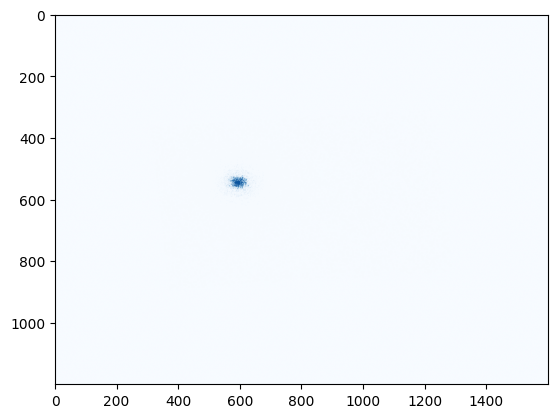

In [422]:
plt.imshow(A_out.detach().cpu().numpy())

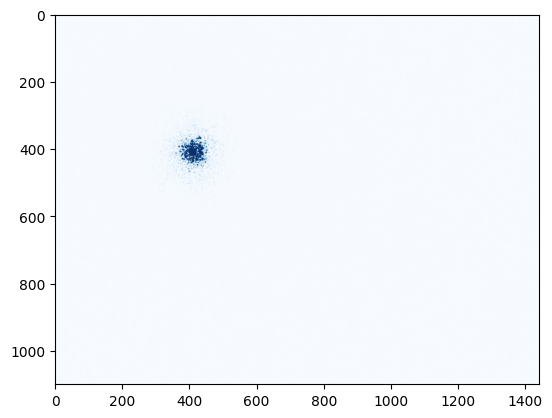

In [423]:
plt.imshow(A_cam)

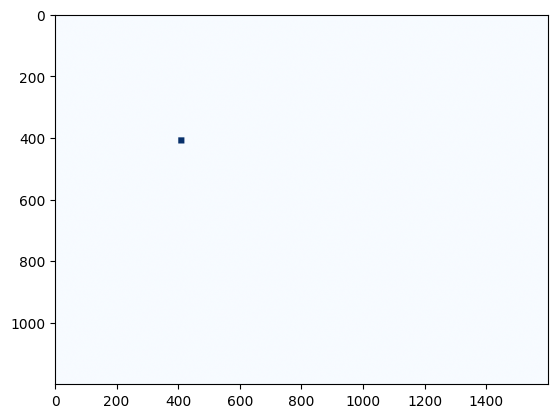

In [424]:
plt.imshow(A_target)

In [356]:
(A_target_norm*A_target_norm).sum(),(A_out*A_out).sum()

(tensor(1.0000), tensor(1.0000, grad_fn=<SumBackward0>))

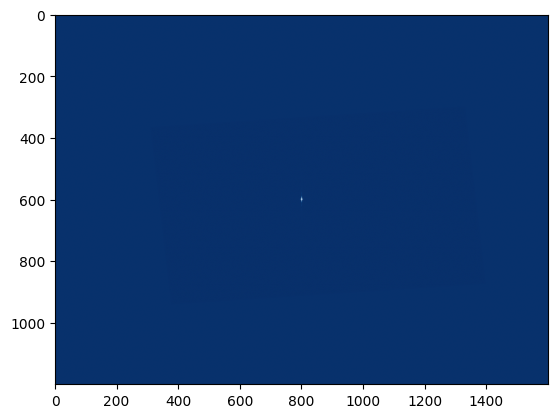

In [336]:
plt.imshow( A_target_norm - A_out.detach() )

In [338]:
A_out.detach() - A_target_norm 

tensor([[0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        ...,
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.]])